# 11.2 - GP/GRG Policy Comparison

6 sampling objectives, three fixed windows and a shared history-only control. The complete six-policy study includes 18 sampled missions; the 7:3 extension reuses the earlier 15. Same frozen GP and 15-minute budget. This Notebook reads saved results without rerunning missions. See README.md for dependencies and commands.

In [1]:
from pathlib import Path
import sys
from IPython.display import Image, Markdown, display
root = Path.cwd()
if not (root / 'testing_code').is_dir():
    root = root / 'Code/11.2_policy_compare'
sys.path.insert(0, str(root / 'testing_code'))
from build_report import verify_saved_results, summary_table
run = root / '11.2_result/strict_plus_70_30_20261103T025338Z'
print('Saved run:', run.name)
verify_saved_results(run)

Saved run: strict_plus_70_30_20261103T025338Z


Verified 84 metric cases; 408 saved execution checks passed.


84

## Mean window RMSE (C)

Lower is better. Each window has equal weight; this is not pooled-record RMSE. Reconstruction uses actual held-out timestamps in the final five minutes. Forecast bins follow the common deadline with the final GP frozen. Other metrics and full per-window results remain in the raw records.

| Policy | Reconstruction | Forecast (0,15] min | Forecast (15,30] min | Forecast (30,60] min |
|---|---:|---:|---:|---:|
| History only | 5.137 | 5.474 | 5.240 | 5.239 |
| MI | 1.239 | 1.395 | 1.860 | 1.953 |
| EMSE | 1.153 | 1.354 | 1.897 | 1.994 |
| MI:EMSE 5:5 | 1.356 | 1.574 | 2.064 | 2.149 |
| MI:EMSE 4:6 | 1.356 | 1.574 | 2.064 | 2.149 |
| MI:EMSE 6:4 | 1.217 | 1.344 | 1.825 | 1.873 |
| MI:EMSE 7:3 | 1.379 | 1.496 | 2.012 | 2.086 |

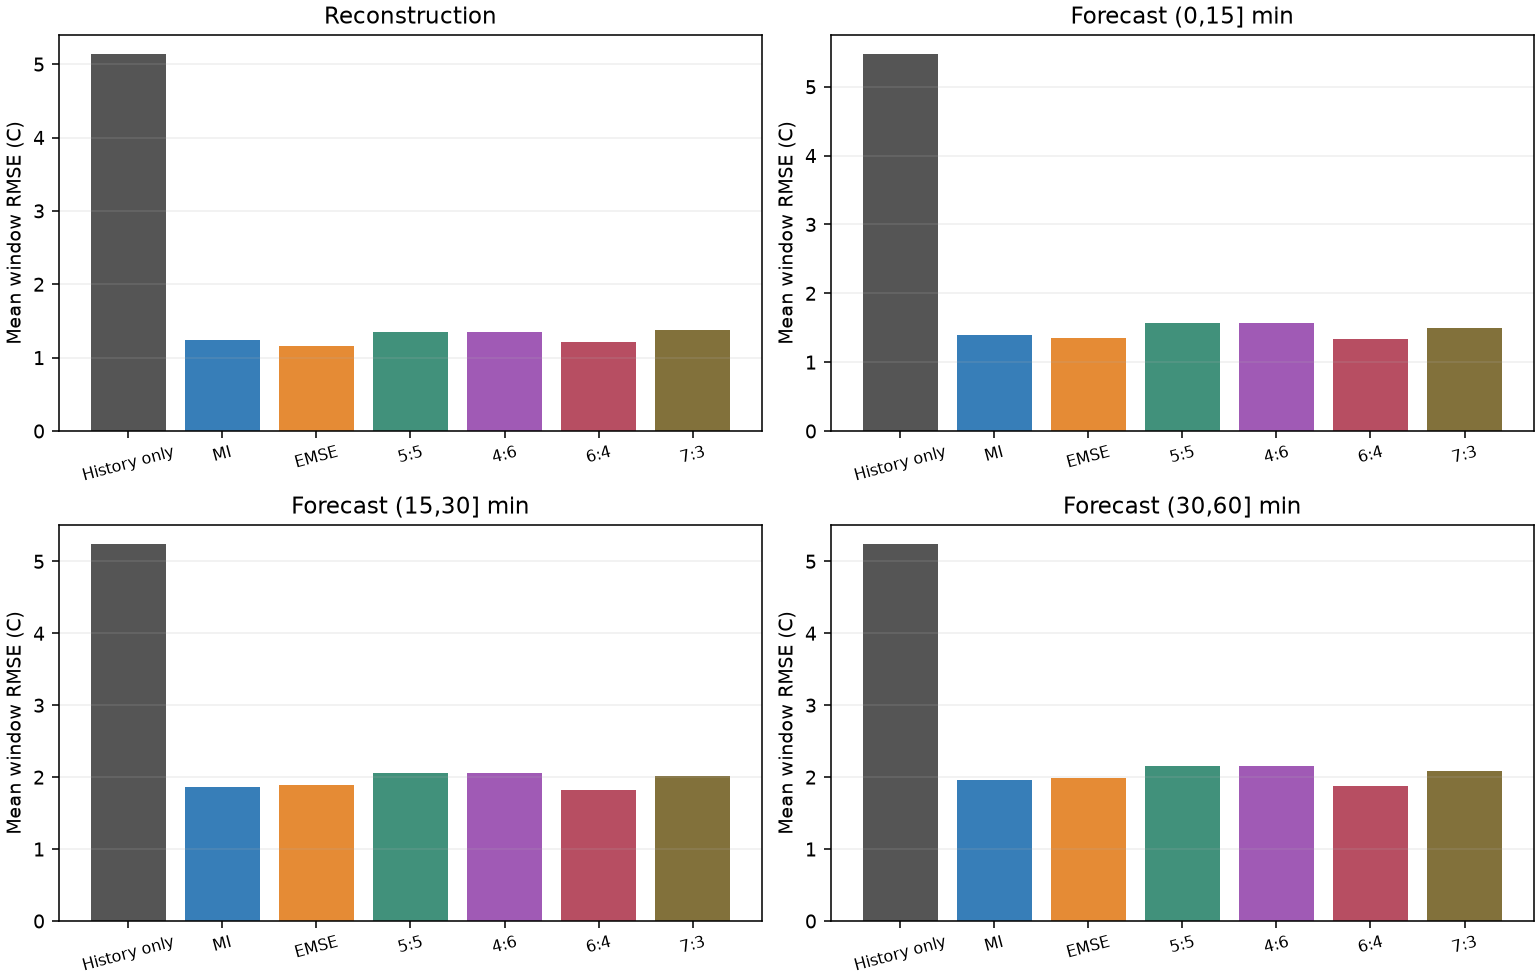

In [2]:
display(Markdown(summary_table(run)))
display(Image(filename=str(root / '11.2_result/report_figures/comparison.png')))

## Forecast variation across time

Windows w00/w08/w16 start at 72/80/88 h. Each resets to the same three-day checkpoint; later windows start with older information. Curves overlap when policies acquire identical records.

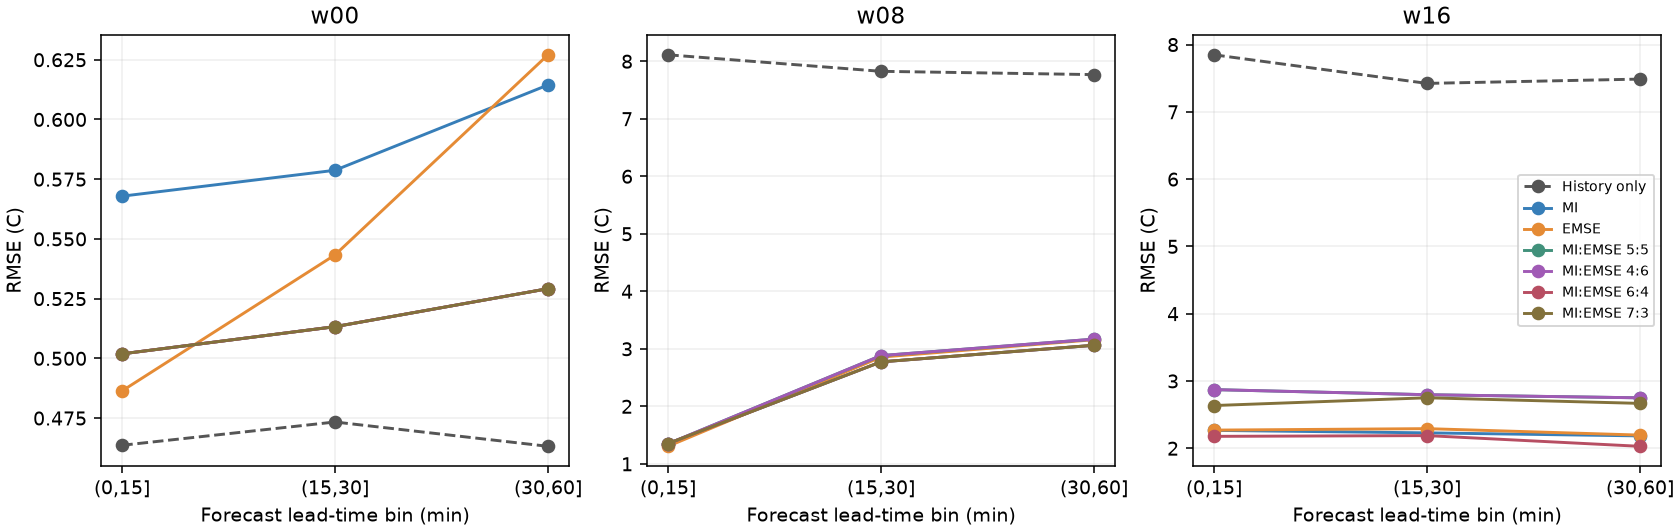

In [3]:
display(Image(filename=str(root / '11.2_result/report_figures/forecast_windows.png')))

## Representative routes: w16

This is where 6:4 and 7:3 diverge. Paths use the Python grid navigator. Dots are candidate sensors; the star is Home. Measurement counts, complete trajectories, waiting time and budgeted return are saved per policy.

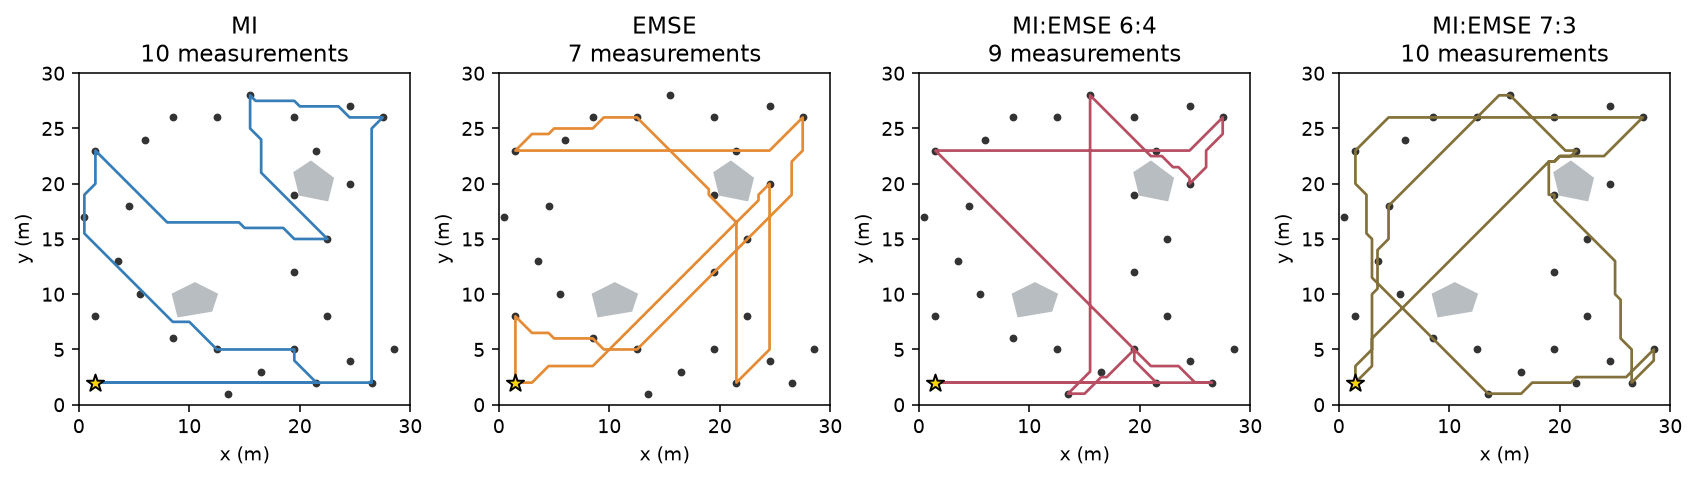

In [4]:
display(Image(filename=str(root / '11.2_result/report_figures/routes_w16.png')))

## Conclusions

- **Reconstruction:** EMSE has the lowest mean RMSE among sampling arms (1.153 C).
- **Forecast (0,15] min:** MI:EMSE 6:4 has the lowest mean RMSE among sampling arms (1.344 C).
- **Forecast (15,30] min:** MI:EMSE 6:4 has the lowest mean RMSE among sampling arms (1.825 C).
- **Forecast (30,60] min:** MI:EMSE 6:4 has the lowest mean RMSE among sampling arms (1.873 C).
- **7:3 versus 6:4:** the first two windows acquire identical records; w16 differs and 7:3 is worse on all four aggregate RMSEs.
- **4:6 and 5:5:** identical acquisitions and results in all three windows.
- At w00, history only beats all sampling arms; later windows benefit from new measurements. Improvement is not uniform across time.
- Keep 6:4 as the current prediction-oriented candidate. Separate-day/field tests are needed before claiming general superiority. EMSE still targets the deadline field, not a future forecast horizon.

[Aggregate CSV](11.2_result/strict_plus_70_30_20261103T025338Z/aggregate.csv) | [Per-window CSV](11.2_result/strict_plus_70_30_20261103T025338Z/evaluation.csv) | [Checks](11.2_result/strict_plus_70_30_20261103T025338Z/verification.json)

These correlated, previously inspected Intel windows support recorded-location reconstruction and future observation prediction; they do not establish dense spatial truth, general optimality or hardware performance.